In [2]:
# import sys
# import subprocess

# print("Python executable:", sys.executable)

# subprocess.run([
#     sys.executable, "-m", "pip",
#     "show", "opencv-python"
# ])

In [3]:
# import sys
# import subprocess

# subprocess.check_call([
#     sys.executable,
#     "-m",
#     "pip",
#     "install",
#     "--upgrade",
#     "pip"
# ])

# subprocess.check_call([
#     sys.executable,
#     "-m",
#     "pip",
#     "install",
#     "opencv-python"
# ])

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("All imports successful!")

OpenCV: 5.0.0
NumPy: 2.5.3
All imports successful!


In [5]:
import numpy as np
import cv2
import matplotlib.pyplot as plt 

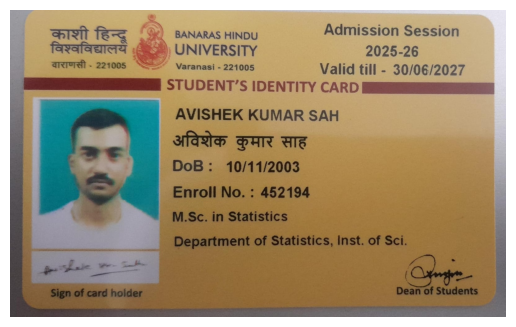

In [6]:
img=cv2.imread("student id.jpeg")
img=cv2.cvtColor(img,cv2.COLOR_BGR2RGB)

plt.figure()
plt.imshow(img)
plt.axis('off')
plt.show()

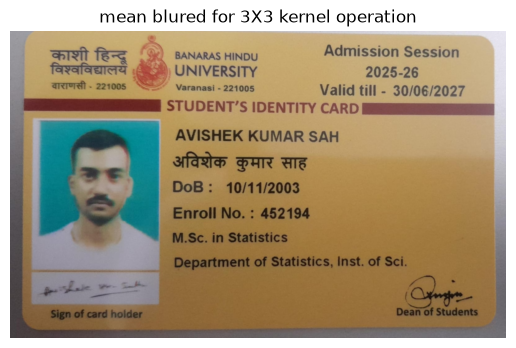

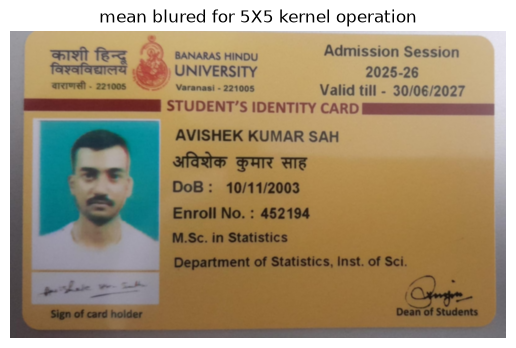

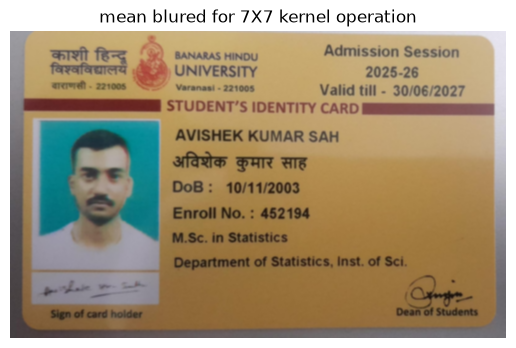

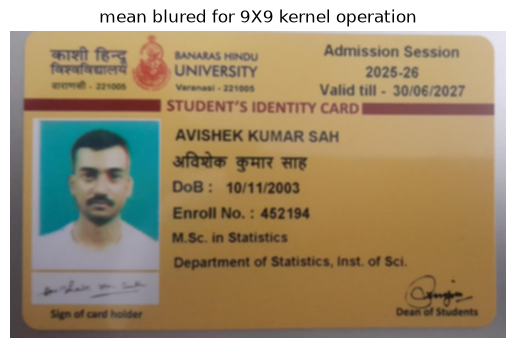

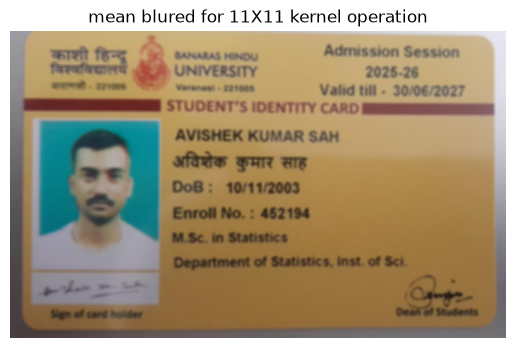

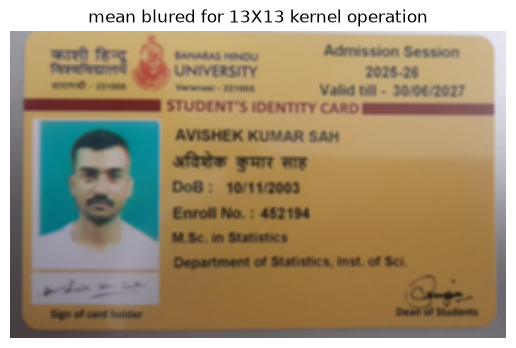

array([[0.11111111, 0.11111111, 0.11111111],
       [0.11111111, 0.11111111, 0.11111111],
       [0.11111111, 0.11111111, 0.11111111]], dtype=float32)

In [7]:
#creating mean blur manually

def meankernel(size):
    mk=np.ones((size,size),dtype=np.float32)/(size**2)
    return mk

for size in range(3,14,2):
    blur_img=cv2.filter2D(img,-1,meankernel(size))
    plt.figure()
    plt.imshow(blur_img)
    plt.title(f"mean blured for {size}X{size} kernel operation")
    plt.axis('off')
    plt.show()

mk=meankernel(3)
mk

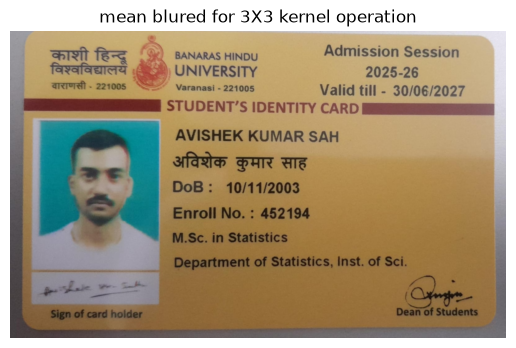

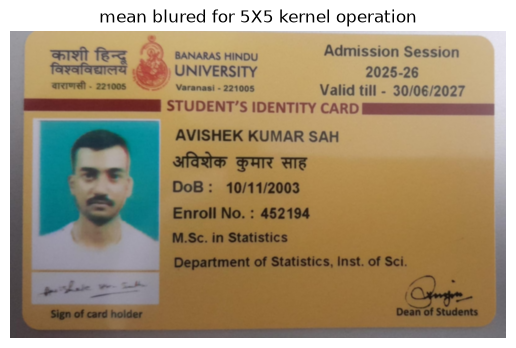

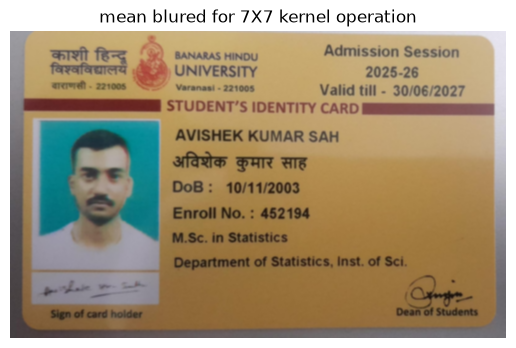

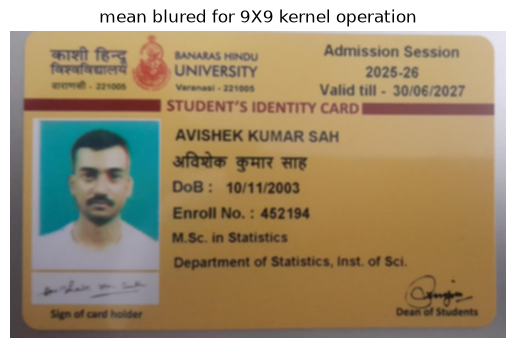

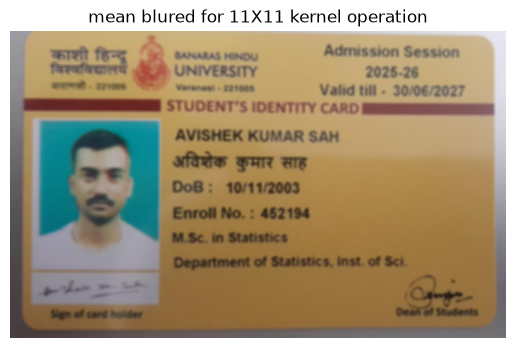

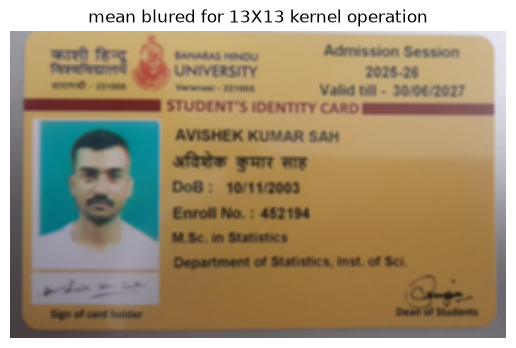

array([[0.11111111, 0.11111111, 0.11111111],
       [0.11111111, 0.11111111, 0.11111111],
       [0.11111111, 0.11111111, 0.11111111]], dtype=float32)

In [8]:
#median blur do it 
def meankernel(size):
    mk=np.ones((size,size),dtype=np.float32)/(size**2)
    return mk

for size in range(3,14,2):
    blur_img=cv2.filter2D(img,-1,meankernel(size))
    plt.figure()
    plt.imshow(blur_img)
    plt.title(f"mean blured for {size}X{size} kernel operation")
    plt.axis('off')
    plt.show()

mk=meankernel(3)
mk

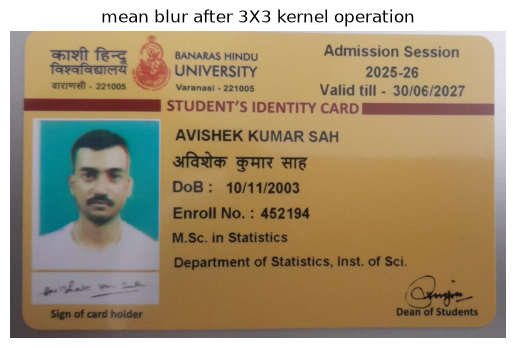

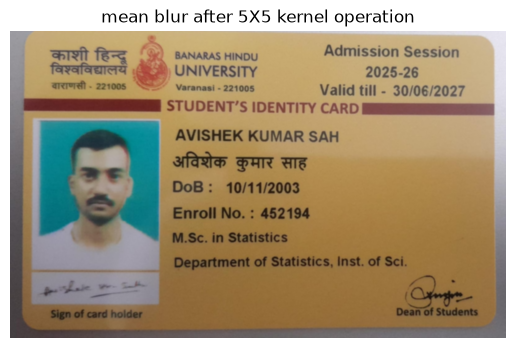

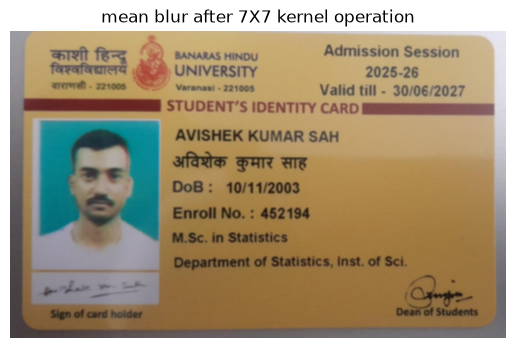

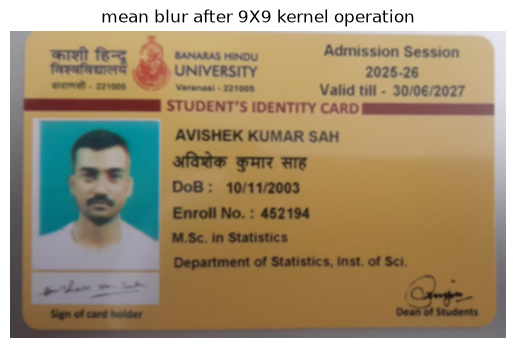

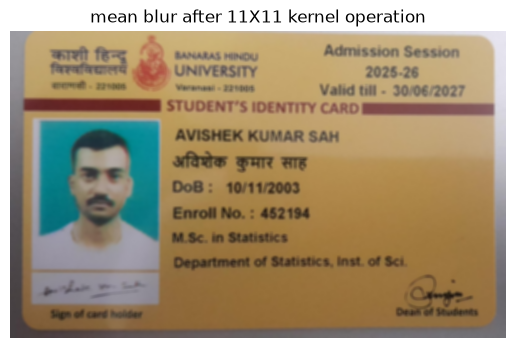

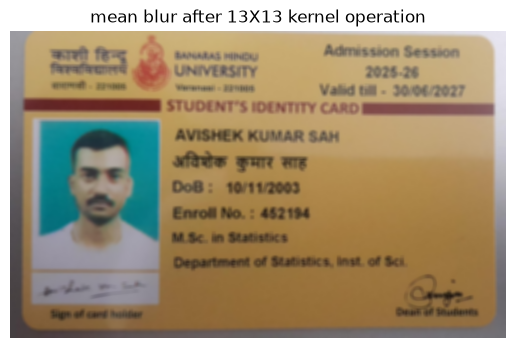

In [9]:
# no need to create kernel manually
for size in range (3,14,2):
    blur_img=cv2.blur(img,(size,size))
    plt.figure()
    plt.imshow(blur_img)
    plt.title(f"mean blur after {size}X{size} kernel operation")
    plt.axis('off')
    plt.show()

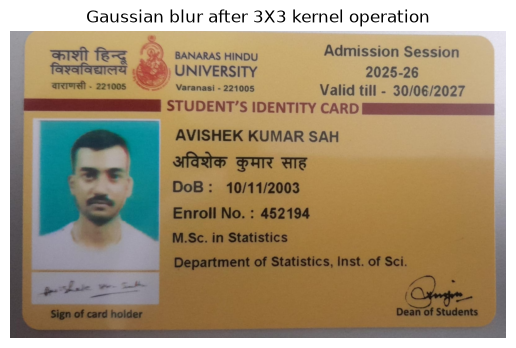

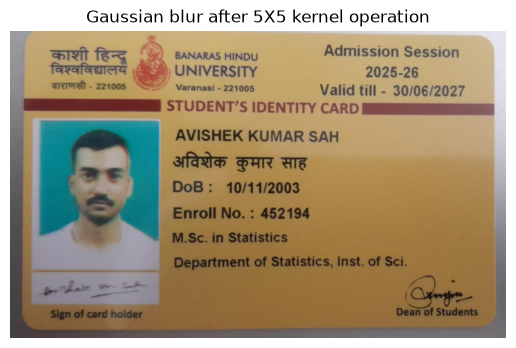

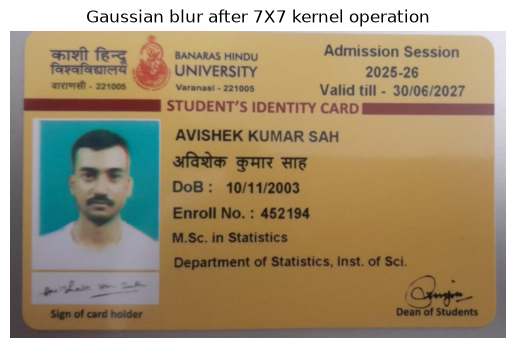

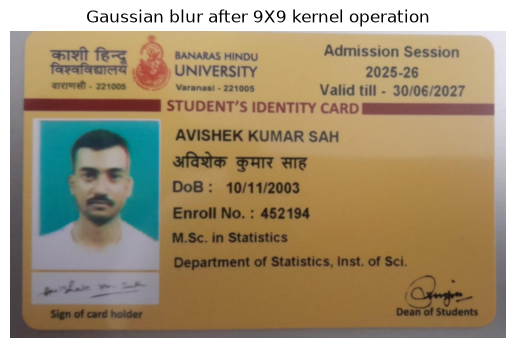

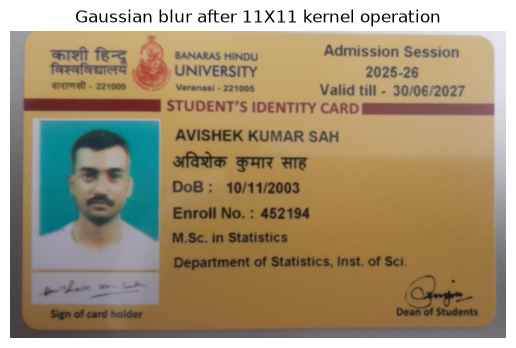

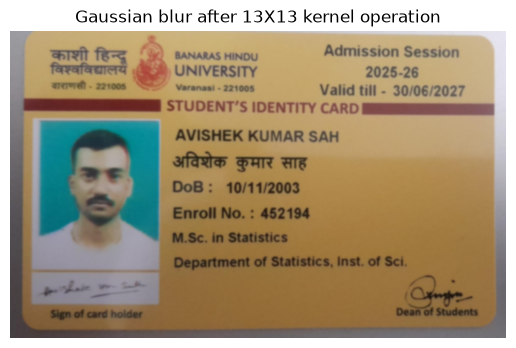

In [10]:
# gaussian blur
for size in range (3,14,2):
    blur_img=cv2.GaussianBlur(img,(size,size),0) 
    #cv2.GaussianBlur(src, kernelsize, sigmaX) extra 0 bcz to calculate automatically gaussian sd in x direction
    plt.figure()
    plt.imshow(blur_img)
    plt.title(f"Gaussian blur after {size}X{size} kernel operation")
    plt.axis('off')
    plt.show()

#### Histogram
* to understand the distribution of pixel we plot histogram
* how many times a pixel has occured

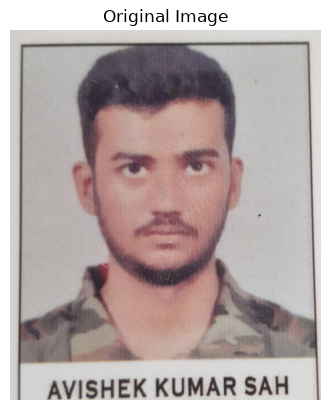

In [11]:
bgr_img=cv2.imread("avi photo.jpeg")
img=cv2.cvtColor(bgr_img,cv2.COLOR_BGR2RGB)
plt.figure()
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [12]:
img.shape

(1225, 1031, 3)

In [13]:
1225*1031*3


3788925

In [14]:
# to flatten the array of 3 dim pixels in one dim
img.ravel().shape

(3788925,)

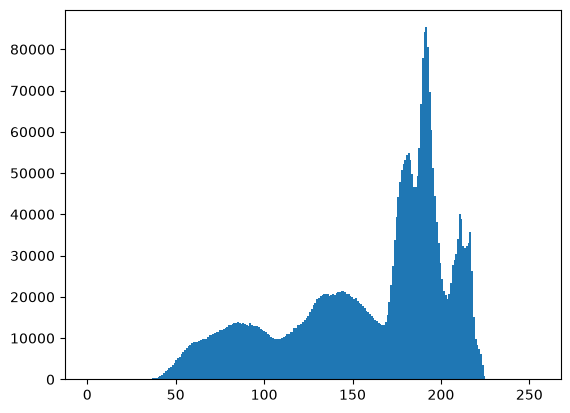

In [15]:
plt.hist(img.ravel(),bins=256,range=[0,255])
plt.show()

# higher the values lighter the color

In [16]:
#to see different channels of distrubution
colors=('b','g','r')
bgr_img_ravel= [bgr_img[:,:,0].ravel(),bgr_img[:,:,1].ravel(),bgr_img[:,:,2].ravel()]
bgr_img_ravel

[array([201, 201, 202, ..., 204, 204, 211], shape=(1262975,), dtype=uint8),
 array([206, 206, 207, ..., 211, 209, 213], shape=(1262975,), dtype=uint8),
 array([209, 209, 210, ..., 214, 212, 214], shape=(1262975,), dtype=uint8)]

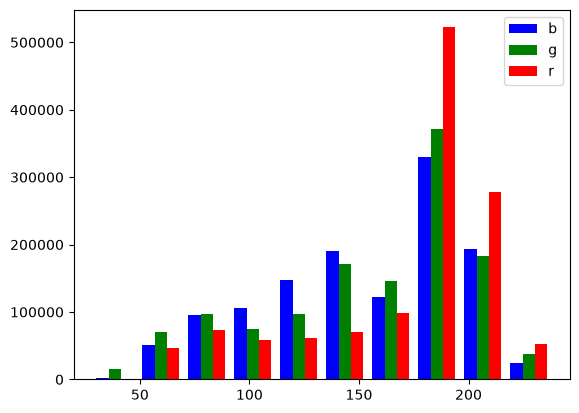

In [17]:
plt.hist(bgr_img_ravel,color=colors,label=colors)
plt.legend()
plt.show()

### Thresholding
  

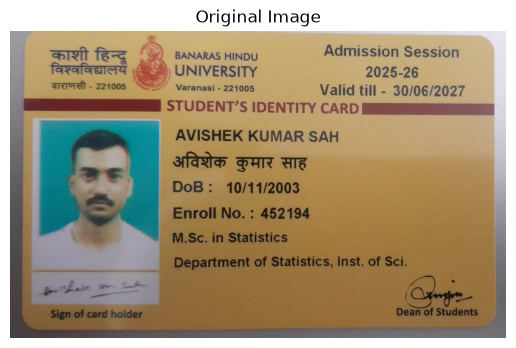

In [18]:
bgr_img=cv2.imread("student id.jpeg")
rgb_img=cv2.cvtColor(bgr_img,cv2.COLOR_BGR2RGB)
plt.figure()
plt.imshow(rgb_img)
plt.title("Original Image")
plt.axis("off")
plt.show() 

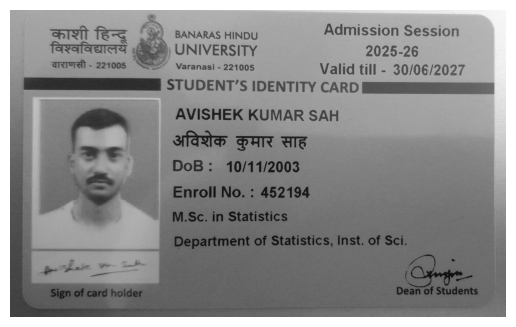

In [19]:
gray_img=cv2.cvtColor(rgb_img,cv2.COLOR_BGR2GRAY)
plt.imshow(gray_img,cmap='gray')
plt.axis("off")
plt.show()

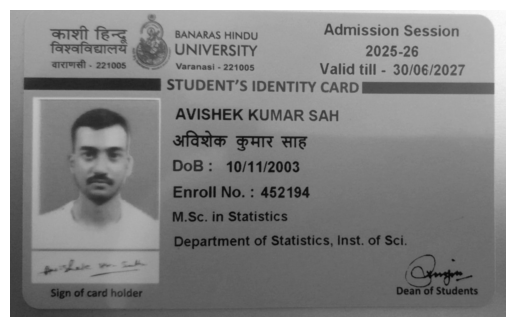

In [20]:
blurred=cv2.GaussianBlur(gray_img,(5,5),0)

plt.imshow(blurred,cmap='gray')
plt.axis('off')
plt.show()

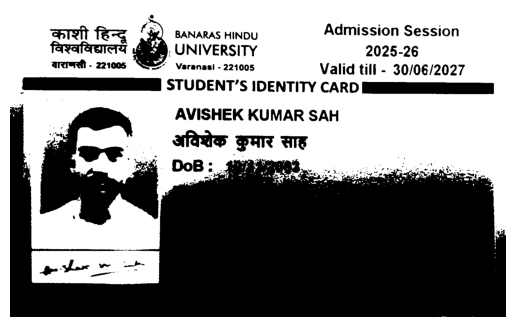

In [21]:
T,thresh=cv2.threshold(blurred,120,255,cv2.THRESH_BINARY)
                              #T,maxval
plt.imshow(thresh,cmap='gray')
plt.axis("off")
plt.show()

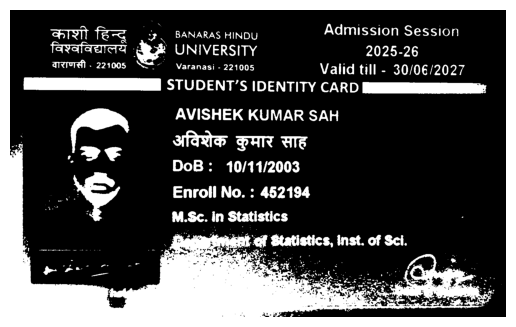

In [22]:
T,thresh=cv2.threshold(blurred,100,255,cv2.THRESH_BINARY_INV)
                              #T,maxval
plt.imshow(thresh,cmap='gray')
plt.axis("off")
plt.show()

#### OTSU Threshold
* to calculate otimum value of T

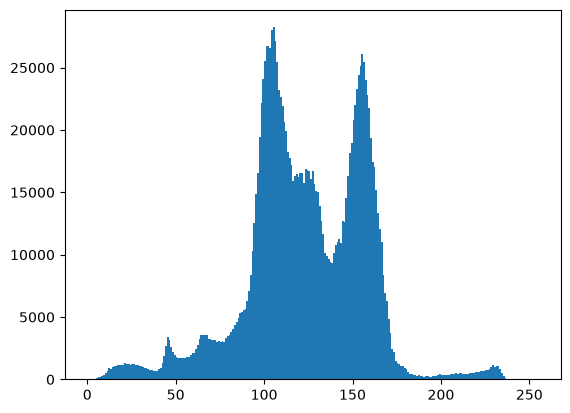

In [23]:
plt.hist(gray_img.ravel(),bins=255,range=[0,255])
plt.show()

[info] otsu's thresholding value: 124.0


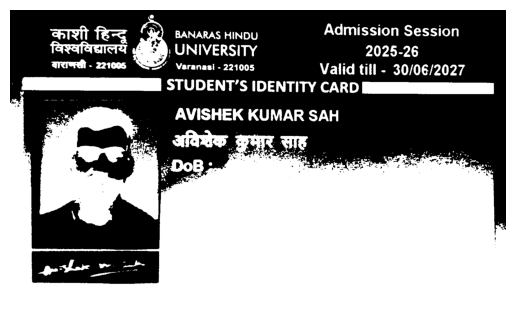

In [24]:
(T,otsu_threshInv)=cv2.threshold(blurred,0,255,
                    cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU)
print("[info] otsu's thresholding value: {}".format(T))

plt.imshow(otsu_threshInv,cmap='Grays_r')
plt.axis("off")
plt.show()


### Adaptive Thresholding
- statistically examine threshold

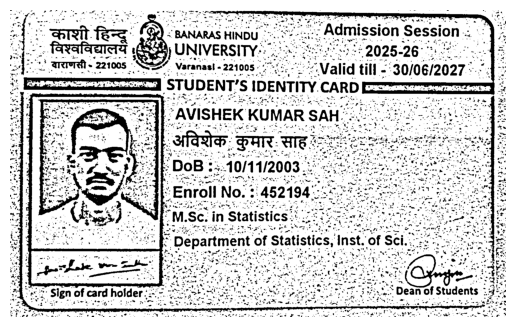

In [25]:
adp_thresh=cv2.adaptiveThreshold(blurred,255,cv2.ADAPTIVE_THRESH_MEAN_C,cv2.THRESH_BINARY,21,2)

plt.imshow(adp_thresh,cmap='Greys_r')
plt.axis("off")
plt.show()

### Contour Detection

contours (0, 0, 1600, 991)
Area 1579677.0


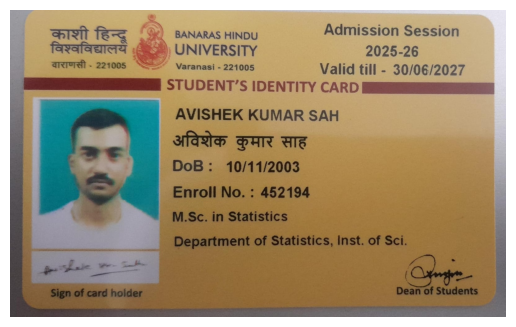

In [26]:
contours,_=cv2.findContours(adp_thresh,mode=cv2.RETR_EXTERNAL,method=cv2.CHAIN_APPROX_SIMPLE)

largest_contour=None
largest_area=0
for cnt in contours:
    area=cv2.contourArea(cnt)
    if area> largest_area:
        largest_contour=cnt
        largest_area=area

x,y,w,h=cv2.boundingRect(largest_contour)

print("contours", (x,y,w,h))
print("Area",largest_area)
contour_id=rgb_img[y:y+h,x:x+w]

plt.imshow(contour_id)
plt.axis('off')
plt.show()

In [27]:
len(contour_id)

991

#### TEXT EXTRACTION
* study about dilation and erosion

In [28]:
import easyocr
reader=easyocr.Reader(['en'])
ocr_result=reader.readtext(contour_id)
result=ocr_result  # keep the original variable name for compatibility with earlier cells
ocr_result
            

Neither CUDA nor MPS are available - defaulting to CPU. Note: This module is much faster with a GPU.
f:\ML DL GenAI\Deep Learning\EKYC using DLCV\.venv\Lib\site-packages\torch\ao\nn\quantized\dynamic\modules\rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\quantized\Quantizer.cpp:116.)
  w_ih = torch.quantize_per_tensor(
f:\ML DL GenAI\Deep Learning\EKYC using DLCV\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


[([[np.int32(121), np.int32(43)],
   [np.int32(270), np.int32(43)],
   [np.int32(270), np.int32(115)],
   [np.int32(121), np.int32(115)]],
  '#r',
  np.float64(0.13678289436007043)),
 ([[np.int32(528), np.int32(59)],
   [np.int32(805), np.int32(59)],
   [np.int32(805), np.int32(104)],
   [np.int32(528), np.int32(104)]],
  'BANARAS HINDU',
  np.float64(0.9999048938936095)),
 ([[np.int32(1008), np.int32(33)],
   [np.int32(1455), np.int32(33)],
   [np.int32(1455), np.int32(97)],
   [np.int32(1008), np.int32(97)]],
  'Admission Session',
  np.float64(0.9992281820104325)),
 ([[np.int32(112), np.int32(43)],
   [np.int32(393), np.int32(43)],
   [np.int32(393), np.int32(158)],
   [np.int32(112), np.int32(158)]],
  '73n',
  np.float64(0.007318219961530632)),
 ([[np.int32(524), np.int32(100)],
   [np.int32(807), np.int32(100)],
   [np.int32(807), np.int32(160)],
   [np.int32(524), np.int32(160)]],
  'UNIVERSITY',
  np.float64(0.8990284673297022)),
 ([[np.int32(1139), np.int32(106)],
   [np.int32

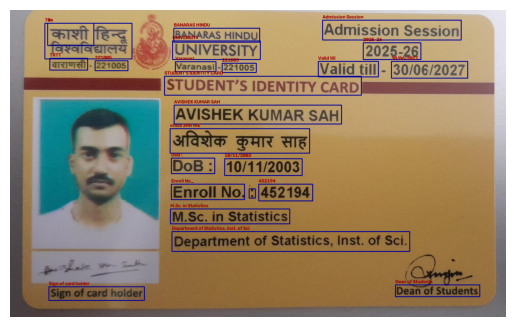

In [29]:
contour_copy = np.copy(contour_id)

for detection in ocr_result:
    bounding_box=detection[0]
    recoginized_text=detection[1]
    confidence=detection[2]

    #conert the bounding box points to integers
    x_min,y_min=map(int,bounding_box[0])
    x_max,y_max=map(int,bounding_box[2])

    #draw a rectangle around the text
    cv2.rectangle(contour_copy,(x_min,y_min),(x_max,y_max),(0,0,155),2)

    #put the recognized text on the image
    cv2.putText(contour_copy,recoginized_text,(x_min,y_min - 5),cv2.FONT_HERSHEY_SIMPLEX,0.5,(155,0,0),2)

plt.imshow(contour_copy)
plt.axis('off')
plt.show()

### Document validation prototype

The next cells turn the EasyOCR result into a practical review workflow:

- clean OCR text and preserve confidence scores
- extract structured fields for a configurable document type
- validate required fields and common formats
- flag low-confidence OCR lines for manual review
- run layout and bounding-box checks when EasyOCR returns boxes
- produce a clear verification summary

Important limitation: these checks can detect inconsistencies, unreadable text, suspicious layout, missing fields, or OCR uncertainty. They do not prove that an ID document is genuine, and they do not prove that the photo came from a live person. Where possible, use the issuer's official or authorized verification service and follow applicable privacy rules before processing real IDs.

In [30]:
import re
import datetime as _dt
from statistics import mean

# EasyOCR returns entries like: (bounding_box, recognized_text, confidence).
# Keep a stable OCR variable because later face-recognition cells also use a
# variable named `result`.
if "ocr_result" not in globals():
    ocr_result = globals().get("result")

if isinstance(ocr_result, dict) and "verified" in ocr_result:
    raise ValueError(
        "`ocr_result` currently looks like DeepFace output. Re-run the EasyOCR cell "
        "or set `ocr_result = reader.readtext(contour_id)` before running validation."
    )


def clean_text(text):
    # Normalize OCR text conservatively without inventing missing characters.
    text = str(text)
    text = text.replace("\n", " ")
    text = re.sub(r"\s+", " ", text).strip()
    text = re.sub(r"^[|:;,\-_.\s]+|[|:;,\-_.\s]+$", "", text)
    return text


def normalize_bbox(box):
    if box is None:
        return None
    try:
        points = [(float(x), float(y)) for x, y in box]
        if len(points) < 2:
            return None
        return points
    except Exception:
        return None


def normalize_ocr_results(raw_results):
    # Convert EasyOCR output into simple rows for extraction and review.
    rows = []
    if raw_results is None:
        return rows

    for idx, item in enumerate(raw_results):
        bbox, text, confidence = None, "", None
        if isinstance(item, (list, tuple)):
            if len(item) >= 3:
                bbox, text, confidence = item[0], item[1], item[2]
            elif len(item) == 2:
                bbox, text = item[0], item[1]
            elif len(item) == 1:
                text = item[0]
        else:
            text = item

        try:
            confidence = None if confidence is None else float(confidence)
        except Exception:
            confidence = None

        cleaned = clean_text(text)
        if cleaned:
            rows.append(
                {
                    "line_no": idx + 1,
                    "raw_text": str(text),
                    "text": cleaned,
                    "confidence": confidence,
                    "bbox": normalize_bbox(bbox),
                }
            )
    return rows


def mask_value(value, keep_start=1, keep_end=1):
    # Mask sensitive values before display. Validation still uses in-memory values.
    if value in (None, ""):
        return ""
    value = str(value)
    if len(value) <= keep_start + keep_end + 2:
        return "*" * len(value)
    return value[:keep_start] + ("*" * (len(value) - keep_start - keep_end)) + value[-keep_end:]


ocr_rows = normalize_ocr_results(ocr_result)
print(f"Prepared {len(ocr_rows)} OCR text rows for validation.")

preview_rows = []
for row in ocr_rows:
    preview_rows.append(
        {
            "line_no": row["line_no"],
            "text_masked": mask_value(row["text"], keep_start=2, keep_end=2),
            "confidence": None if row["confidence"] is None else round(row["confidence"], 3),
            "has_bbox": row["bbox"] is not None,
        }
    )

try:
    import pandas as pd
    display(pd.DataFrame(preview_rows))
except Exception:
    for row in preview_rows:
        print(row)

Prepared 23 OCR text rows for validation.


,line_no,text_masked,confidence,has_bbox
0,1,**,0.137,True
1,2,BA*********DU,1.000,True
2,3,Ad*************on,0.999,True
3,4,***,0.007,True
4,5,UN******TY,0.899,True
5,6,20***26,1.000,True
6,7,****,0.246,True
7,8,******,1.000,True
8,9,Va****si,0.959,True
9,10,******,1.000,True


In [31]:
# Choose the document profile that best matches your input.
# Add or edit field patterns here for a specific issuer or campus format.
DOCUMENT_TYPE = "student_id"  # options: "student_id", "generic_id"

DOCUMENT_CONFIGS = {
    "student_id": {
        "required_fields": ["name", "id_number"],
        "fields": {
            "name": {
                "labels": ["name", "student name"],
                "validator": "person_name",
                "sensitive": True,
            },
            "id_number": {
                "labels": ["id", "id no", "id number", "student id", "roll no", "registration no", "reg no"],
                "fallback_patterns": [r"\b[A-Z0-9][A-Z0-9\-\/]{3,}\b"],
                "validator": "id_number",
                "sensitive": True,
            },
            "date_of_birth": {
                "labels": ["dob", "d.o.b", "date of birth", "birth date"],
                "fallback_patterns": [r"\b\d{1,2}[\/\-.]\d{1,2}[\/\-.]\d{2,4}\b"],
                "validator": "past_date",
                "sensitive": True,
            },
            "expiry_date": {
                "labels": ["valid until", "valid upto", "expiry", "expires", "exp date"],
                "validator": "not_expired",
                "sensitive": True,
            },
        },
    },
    "generic_id": {
        "required_fields": ["document_number"],
        "fields": {
            "name": {
                "labels": ["name", "full name"],
                "validator": "person_name",
                "sensitive": True,
            },
            "document_number": {
                "labels": ["document no", "document number", "id no", "id number", "number"],
                "fallback_patterns": [r"\b[A-Z0-9][A-Z0-9\-\/]{4,}\b"],
                "validator": "id_number",
                "sensitive": True,
            },
            "date_of_birth": {
                "labels": ["dob", "date of birth", "birth date"],
                "fallback_patterns": [r"\b\d{1,2}[\/\-.]\d{1,2}[\/\-.]\d{2,4}\b"],
                "validator": "past_date",
                "sensitive": True,
            },
            "expiry_date": {
                "labels": ["valid until", "valid upto", "expiry", "expires", "exp date"],
                "validator": "not_expired",
                "sensitive": True,
            },
        },
    },
}


def _label_regex(labels):
    escaped = [re.escape(label) for label in labels]
    return r"(?:{})".format("|".join(escaped))


def find_label_value(ocr_rows, labels):
    # Find values from lines such as 'Name: Jane Doe' or label on one line and value on the next.
    label_re = _label_regex(labels)
    for i, row in enumerate(ocr_rows):
        text = row["text"]
        match = re.search(label_re + r"\s*[:#\-]?\s*(.+)$", text, flags=re.IGNORECASE)
        if match:
            value = clean_text(match.group(1))
            # Avoid returning only the label itself.
            if value and not re.fullmatch(label_re, value, flags=re.IGNORECASE):
                return value, [row]
            if i + 1 < len(ocr_rows):
                return ocr_rows[i + 1]["text"], [row, ocr_rows[i + 1]]

        if re.fullmatch(label_re + r"\s*[:#\-]?", text, flags=re.IGNORECASE) and i + 1 < len(ocr_rows):
            return ocr_rows[i + 1]["text"], [row, ocr_rows[i + 1]]

    return None, []


def find_pattern_value(ocr_rows, patterns):
    full_text = "\n".join(row["text"] for row in ocr_rows)
    for pattern in patterns:
        match = re.search(pattern, full_text, flags=re.IGNORECASE)
        if match:
            value = match.group(1) if match.groups() else match.group(0)
            supporting_rows = [row for row in ocr_rows if value in row["text"]]
            return clean_text(value), supporting_rows
    return None, []


def average_confidence(rows):
    scores = [row["confidence"] for row in rows if row["confidence"] is not None]
    return None if not scores else mean(scores)


def extract_fields(ocr_rows, document_type):
    config = DOCUMENT_CONFIGS[document_type]
    extracted = {}
    for field_name, field_config in config["fields"].items():
        value, supporting_rows = find_label_value(ocr_rows, field_config.get("labels", []))
        if not value:
            value, supporting_rows = find_pattern_value(ocr_rows, field_config.get("fallback_patterns", []))

        extracted[field_name] = {
            "value": value,
            "masked_value": mask_value(value, keep_start=2, keep_end=2) if field_config.get("sensitive") else value,
            "confidence": average_confidence(supporting_rows),
            "source_lines": [row["line_no"] for row in supporting_rows],
            "required": field_name in config["required_fields"],
            "validator": field_config.get("validator"),
        }
    return extracted


if DOCUMENT_TYPE not in DOCUMENT_CONFIGS:
    raise ValueError(f"Unknown DOCUMENT_TYPE: {DOCUMENT_TYPE}")

extracted_fields = extract_fields(ocr_rows, DOCUMENT_TYPE)

try:
    import pandas as pd
    display(pd.DataFrame([
        {
            "field": field,
            "value_masked": info["masked_value"],
            "required": info["required"],
            "confidence": None if info["confidence"] is None else round(info["confidence"], 3),
            "source_lines": info["source_lines"],
        }
        for field, info in extracted_fields.items()
    ]))
except Exception:
    for field, info in extracted_fields.items():
        print(field, {k: v for k, v in info.items() if k != "value"})

,field,value_masked,required,confidence,source_lines
0,name,,True,NaN,[]
1,id_number,****,True,0.875,[11]
2,date_of_birth,10******03,False,0.969,"[16, 17]"
3,expiry_date,,False,NaN,[]


In [32]:
def parse_date(value):
    if not value:
        return None
    value = clean_text(value)
    formats = ["%d/%m/%Y", "%d-%m-%Y", "%d.%m.%Y", "%m/%d/%Y", "%m-%d-%Y", "%Y-%m-%d", "%d/%m/%y", "%m/%d/%y"]
    for fmt in formats:
        try:
            return _dt.datetime.strptime(value, fmt).date()
        except ValueError:
            pass
    return None


def validate_value(field, value, validator):
    if not value:
        return False, "missing"

    if validator == "person_name":
        letters = re.sub(r"[^A-Za-z]", "", value)
        if len(letters) < 3:
            return False, "name is too short or OCR did not read enough letters"
        if re.search(r"\d", value):
            return False, "name contains digits"
        return True, "looks like a readable name"

    if validator == "id_number":
        compact = re.sub(r"\s+", "", value)
        if len(compact) < 4:
            return False, "ID/document number is too short"
        if not re.search(r"[A-Za-z0-9]", compact):
            return False, "ID/document number has no letters or digits"
        return True, "format is plausible"

    if validator in {"past_date", "not_expired"}:
        parsed = parse_date(value)
        if parsed is None:
            return False, "date could not be parsed"
        today = _dt.date.today()
        if validator == "past_date" and parsed >= today:
            return False, "date is not in the past"
        if validator == "not_expired" and parsed < today:
            return False, "document appears expired"
        return True, f"parsed as {parsed.isoformat()}"

    return True, "no validator configured"


FIELD_CONFIDENCE_THRESHOLD = 0.55

validation_results = []
for field, info in extracted_fields.items():
    ok, message = validate_value(field, info["value"], info["validator"])
    confidence = info["confidence"]
    if confidence is not None and confidence < FIELD_CONFIDENCE_THRESHOLD:
        ok = False
        message = message + f"; low OCR confidence ({confidence:.2f})"
    validation_results.append(
        {
            "field": field,
            "required": info["required"],
            "present": bool(info["value"]),
            "value_masked": info["masked_value"],
            "confidence": None if confidence is None else round(confidence, 3),
            "passed": ok,
            "message": message,
        }
    )

try:
    import pandas as pd
    display(pd.DataFrame(validation_results))
except Exception:
    for item in validation_results:
        print(item)

,field,required,present,value_masked,confidence,passed,message
0,name,True,False,,NaN,False,missing
1,id_number,True,True,****,0.875,True,format is plausible
2,date_of_birth,False,True,10******03,0.969,True,parsed as 2003-11-10
3,expiry_date,False,False,,NaN,False,missing


Low-confidence OCR lines:
{'line_no': 1, 'text_masked': '**', 'confidence': 0.137}
{'line_no': 4, 'text_masked': '***', 'confidence': 0.007}
{'line_no': 7, 'text_masked': '****', 'confidence': 0.246}
{'line_no': 15, 'text_masked': 'ef*********lE', 'confidence': 0.019}

Layout checks:
PASS: bounding_boxes_present - 23 OCR boxes found.
PASS: valid_box_geometry - All boxes have positive width/height.
PASS: boxes_inside_image - All boxes are inside the image.
PASS: box_size_reasonable - Text box sizes look reasonable.
PASS: enough_text_regions - 23 text regions found.


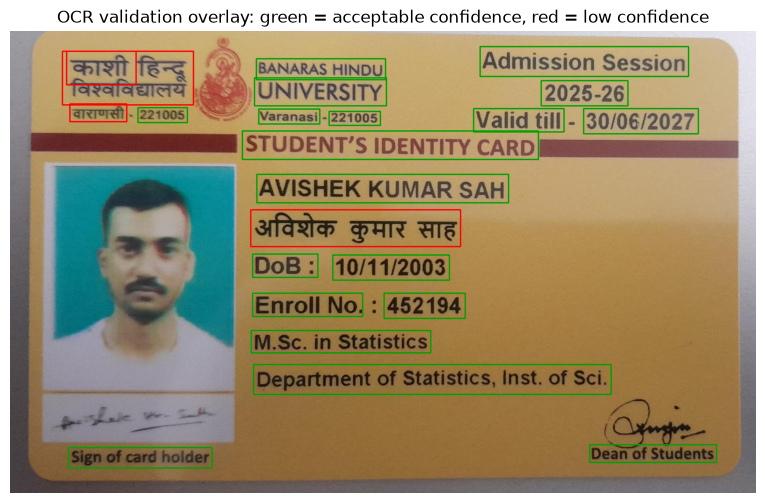

In [33]:
OCR_CONFIDENCE_THRESHOLD = 0.55


def bbox_rect(bbox):
    if not bbox:
        return None
    xs = [point[0] for point in bbox]
    ys = [point[1] for point in bbox]
    return min(xs), min(ys), max(xs), max(ys)


def review_ocr_confidence(ocr_rows, threshold=OCR_CONFIDENCE_THRESHOLD):
    return [
        {
            "line_no": row["line_no"],
            "text_masked": mask_value(row["text"], keep_start=2, keep_end=2),
            "confidence": round(row["confidence"], 3),
        }
        for row in ocr_rows
        if row["confidence"] is not None and row["confidence"] < threshold
    ]


def run_layout_checks(ocr_rows, image=None):
    checks = []
    rows_with_boxes = [row for row in ocr_rows if row["bbox"] is not None]

    if not rows_with_boxes:
        return [
            {
                "check": "bounding_boxes_present",
                "passed": False,
                "message": "No EasyOCR bounding boxes available. Re-run EasyOCR with detail=1.",
            }
        ]

    checks.append(
        {
            "check": "bounding_boxes_present",
            "passed": True,
            "message": f"{len(rows_with_boxes)} OCR boxes found.",
        }
    )

    image_h = image_w = None
    if image is not None and hasattr(image, "shape"):
        image_h, image_w = image.shape[:2]

    invalid_boxes = []
    out_of_bounds = []
    tiny_boxes = []
    very_large_boxes = []
    for row in rows_with_boxes:
        rect = bbox_rect(row["bbox"])
        if rect is None:
            invalid_boxes.append(row["line_no"])
            continue
        x1, y1, x2, y2 = rect
        width, height = x2 - x1, y2 - y1
        if width <= 0 or height <= 0:
            invalid_boxes.append(row["line_no"])
        if image_w and image_h:
            if x1 < 0 or y1 < 0 or x2 > image_w or y2 > image_h:
                out_of_bounds.append(row["line_no"])
            area_ratio = (width * height) / float(image_w * image_h)
            if area_ratio < 0.00002:
                tiny_boxes.append(row["line_no"])
            if area_ratio > 0.35:
                very_large_boxes.append(row["line_no"])

    checks.extend(
        [
            {
                "check": "valid_box_geometry",
                "passed": not invalid_boxes,
                "message": "All boxes have positive width/height." if not invalid_boxes else f"Invalid boxes on lines {invalid_boxes}.",
            },
            {
                "check": "boxes_inside_image",
                "passed": not out_of_bounds,
                "message": "All boxes are inside the image." if not out_of_bounds else f"Boxes outside image on lines {out_of_bounds}.",
            },
            {
                "check": "box_size_reasonable",
                "passed": not tiny_boxes and not very_large_boxes,
                "message": "Text box sizes look reasonable." if not tiny_boxes and not very_large_boxes else f"Tiny boxes: {tiny_boxes}; very large boxes: {very_large_boxes}.",
            },
            {
                "check": "enough_text_regions",
                "passed": len(rows_with_boxes) >= 3,
                "message": f"{len(rows_with_boxes)} text regions found.",
            },
        ]
    )
    return checks


low_confidence_lines = review_ocr_confidence(ocr_rows)
layout_checks = run_layout_checks(ocr_rows, image=globals().get("contour_id"))

print("Low-confidence OCR lines:")
if low_confidence_lines:
    for item in low_confidence_lines:
        print(item)
else:
    print("None below threshold.")

print("\nLayout checks:")
for check in layout_checks:
    status = "PASS" if check["passed"] else "REVIEW"
    print(f"{status}: {check['check']} - {check['message']}")


def draw_validation_overlay(image, ocr_rows, low_threshold=OCR_CONFIDENCE_THRESHOLD):
    if image is None:
        print("No image variable found for overlay.")
        return None
    overlay = np.copy(image)
    for row in ocr_rows:
        rect = bbox_rect(row["bbox"])
        if rect is None:
            continue
        x1, y1, x2, y2 = [int(v) for v in rect]
        color = (255, 0, 0) if row["confidence"] is not None and row["confidence"] < low_threshold else (0, 160, 0)
        cv2.rectangle(overlay, (x1, y1), (x2, y2), color, 2)
    return overlay


validation_overlay = draw_validation_overlay(globals().get("contour_id"), ocr_rows)
if validation_overlay is not None:
    plt.figure(figsize=(10, 6))
    plt.imshow(validation_overlay)
    plt.axis("off")
    plt.title("OCR validation overlay: green = acceptable confidence, red = low confidence")
    plt.show()

In [34]:
def build_verification_summary(validation_results, low_confidence_lines, layout_checks):
    required_failures = [
        item for item in validation_results
        if item["required"] and (not item["present"] or not item["passed"])
    ]
    optional_failures = [
        item for item in validation_results
        if not item["required"] and item["present"] and not item["passed"]
    ]
    failed_layout = [item for item in layout_checks if not item["passed"]]

    if required_failures or failed_layout:
        status = "Needs manual review"
    elif low_confidence_lines or optional_failures:
        status = "Passed basic checks with warnings"
    else:
        status = "No obvious inconsistencies found in basic checks"

    return {
        "status": status,
        "required_field_issues": required_failures,
        "optional_field_warnings": optional_failures,
        "low_confidence_line_count": len(low_confidence_lines),
        "layout_issues": failed_layout,
        "limitations": (
            "This prototype checks OCR readability, field consistency, and layout signals only. "
            "It does not prove document authenticity, confirm issuer records, detect every tamper, "
            "or prove that a face image came from a live person. Use official or authorized "
            "verification where available."
        ),
    }


verification_summary = build_verification_summary(validation_results, low_confidence_lines, layout_checks)

print("Verification summary")
print("====================")
print("Status:", verification_summary["status"])
print("Low-confidence OCR lines:", verification_summary["low_confidence_line_count"])

if verification_summary["required_field_issues"]:
    print("\nRequired field issues:")
    for item in verification_summary["required_field_issues"]:
        print(f"- {item['field']}: {item['message']} (value: {item['value_masked']})")

if verification_summary["optional_field_warnings"]:
    print("\nOptional field warnings:")
    for item in verification_summary["optional_field_warnings"]:
        print(f"- {item['field']}: {item['message']} (value: {item['value_masked']})")

if verification_summary["layout_issues"]:
    print("\nLayout issues:")
    for item in verification_summary["layout_issues"]:
        print(f"- {item['check']}: {item['message']}")

print("\nLimitations:")
print(verification_summary["limitations"])

Verification summary
Status: Needs manual review
Low-confidence OCR lines: 4

Required field issues:
- name: missing (value: )

Limitations:
This prototype checks OCR readability, field consistency, and layout signals only. It does not prove document authenticity, confirm issuer records, detect every tamper, or prove that a face image came from a live person. Use official or authorized verification where available.


#### Face Detection
* feature based object detection algorithm to detect object from images.

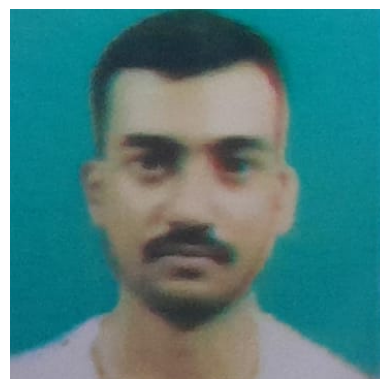

In [35]:
cascade_path="haarcascade_frontalface_default.xml"
gray_img = cv2.cvtColor(contour_id,cv2.COLOR_BGR2GRAY)

#load the haar cascade classifier
face_cascade=cv2.CascadeClassifier(cascade_path)

#Detect faces in the image
faces= face_cascade.detectMultiScale(gray_img,scaleFactor=1.1,minNeighbors=5)

#faces

# find the face with largest area
max_area = 0 
largest_face=None
for (x,y,w,h) in faces:
    area=w*h
    if area> max_area:
        max_area=area
        largest_face=(x,y,w,h)

#Extract the largest face
if largest_face is not None:
    (x,y,w,h)  = largest_face
    #extracted_face img[y:y+h,x+w]

    #increase dimensions by 15%
    new_w = int(w*1.50)
    new_h=int(h*1.50)

    new_x=max(0,x-int((new_w-w)/2))
    new_y=max(0,y-int((new_h-h)/2))

    #calculate new (x,y)  coordinates to keep the center of the face the same 
    extracted_face = contour_id[new_y:new_y+new_h,new_x:new_x+new_w]

plt.imshow(extracted_face)
plt.axis("off")
plt.show()


In [36]:
cv2.imwrite("extracted_face.jpg",extracted_face)

True

#### Face Recognition
* Dlib: Dlib is a C++ lib with python bindings known for its excellent face detection and shape prediction capabilities . it alo includes a pre-trained face recognition model

* face_recognition: python lib built on top of dlib and provides a simple api for face recognition tasks . it offers both face detection and recognition functionalities


In [37]:
from deepface import DeepFace

result = DeepFace.verify(
    img1_path="student id.jpeg",
    img2_path="avi photo.jpeg",
    model_name="Facenet512",
    detector_backend="opencv"
)

print("Verified:", result["verified"])
print("Distance:", result["distance"])

Verified: True
Distance: 0.249638


In [38]:
print("Verified:", result["verified"])
print("Distance:", result["distance"])
print("Threshold:", result["threshold"])
print("Model:", result["model"])
print("Detector:", result["detector_backend"])

Verified: True
Distance: 0.249638
Threshold: 0.3
Model: Facenet512
Detector: opencv
